# Trabajo académico — Clasificación de imágenes médicas en OrganAMNIST (MedMNIST+)

**Reconocimiento de Formas y Aprendizaje Automático (RFA) — Curso 2026/27**
**Autor:** _(Carlos Broch Cubedo)_
**Dataset:** OrganAMNIST (MedMNIST+), resolución 64×64 (`organamnist_64.npz`)

Esta memoria sigue la estructura recomendada en TL10 (Trabajo académico): se documentan experimentos sucesivos con el dataset escogido, en paralelo con los contenidos de cada sesión de laboratorio (TL01–TL09), y se cierra con una comparativa de resultados y las conclusiones.

## Índice

1. [Introducción](#1.-Introducción)
2. [Librerías y datos (TL01)](#2.-Librerías-y-datos-(TL01))
3. [Análisis de componentes principales — PCA (TL02)](#3.-Análisis-de-componentes-principales-—-PCA-(TL02))
4. [Análisis discriminante (TL03)](#4.-Análisis-discriminante-(TL03))
5. [Regresión logística (TL04)](#5.-Regresión-logística-(TL04))
6. [Regresión lineal (TL05)](#6.-Regresión-lineal-(TL05))
7. [Redes neuronales con PyTorch (TL06)](#7.-Redes-neuronales-con-PyTorch-(TL06))
8. [Modelos preentrenados con timm (TL07)](#8.-Modelos-preentrenados-con-timm-(TL07))
9. [Schedulers (TL08)](#9.-Schedulers-(TL08))
10. [Aumento de datos (TL09)](#10.-Aumento-de-datos-(TL09))
11. [Modelos no paramétricos](#11-modelos-no-paramétricos-bosques-aleatorios-y-xgboost)
12. [Resultados y comparativa global](#12.-Resultados-y-comparativa-global)
13. [Conclusiones](#13.-Conclusiones)
14. [Referencias](#14.-Referencias)

## 1. Introducción

**Tema:** clasificación de imágenes médicas (cortes de TC abdominal) en 11 clases de órganos, usando el dataset **OrganAMNIST** de la colección MedMNIST+.

**Motivación / complejidad del problema:** OrganAMNIST tiene 11 clases, imágenes en escala de grises con variabilidad anatómica entre cortes axiales, y forma parte de un benchmark médico usado en la literatura (MedMNIST v2, Yang et al.) con resultados publicados que sirven de referencia para comparar.

**Dataset escogido:** OrganAMNIST (MedMNIST+), imágenes de 64×64 píxeles en escala de grises, cargadas desde `organamnist_64.npz`.



## 2. Librerías y datos (TL01)

Carga y exploración inicial del dataset con las librerías básicas de Python para ML (`numpy`, `scikit-learn`).

En esta sección:
- Cargar `train` / `val` / `test` desde el `.npz` y mostrar las dimensiones de cada partición.
- Comprobar el balance de clases (11 clases de órganos).
- Visualizar una muestra de imágenes por clase.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

data = np.load('../data/organamnist_64.npz')
print(list(data.keys()))

x_train, y_train = data['train_images'], data['train_labels'].ravel()
x_val, y_val = data['val_images'], data['val_labels'].ravel()
x_test, y_test = data['test_images'], data['test_labels'].ravel()

print('train:', x_train.shape, y_train.shape)
print('val:  ', x_val.shape, y_val.shape)
print('test: ', x_test.shape, y_test.shape)
print('clases:', np.unique(y_train))


['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
train: (34561, 64, 64) (34561,)
val:   (6491, 64, 64) (6491,)
test:  (17778, 64, 64) (17778,)
clases: [ 0  1  2  3  4  5  6  7  8  9 10]


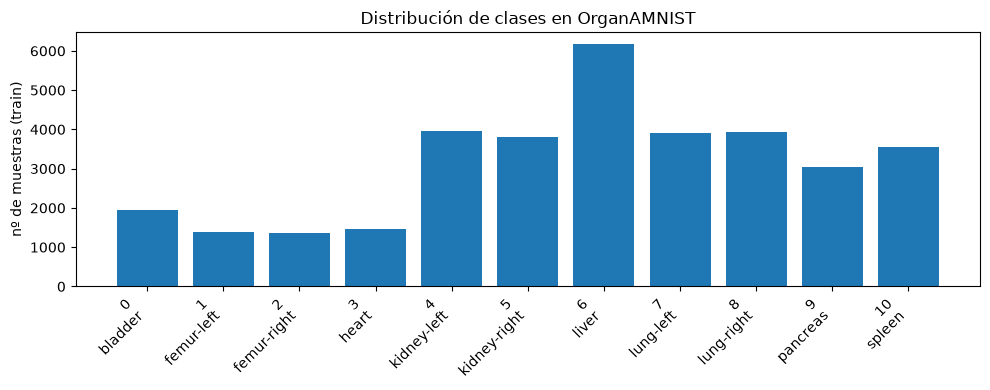

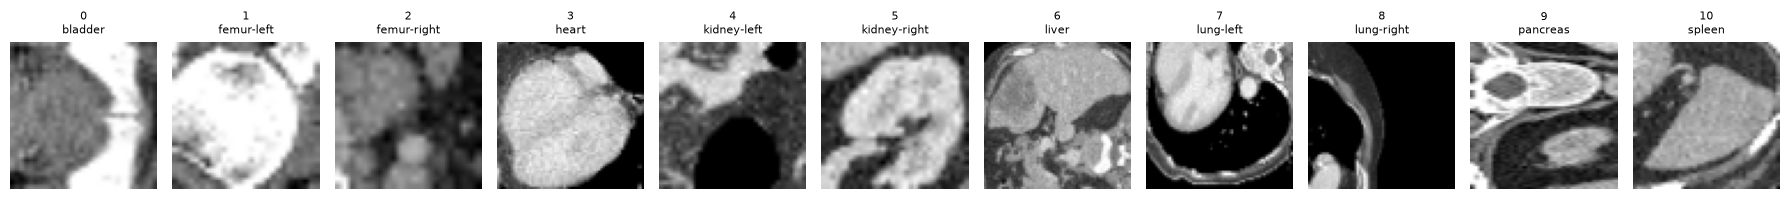

In [2]:
organ_names = {
    0: 'bladder', 1: 'femur-left', 2: 'femur-right', 3: 'heart',
    4: 'kidney-left', 5: 'kidney-right', 6: 'liver', 7: 'lung-left',
    8: 'lung-right', 9: 'pancreas', 10: 'spleen'
}

# Distribución de clases (train)
counts = np.bincount(y_train, minlength=11)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(11), counts)
ax.set_xticks(range(11))
ax.set_xticklabels([f'{c}\n{organ_names[c]}' for c in range(11)], rotation=45, ha='right')
ax.set_ylabel('nº de muestras (train)')
ax.set_title('Distribución de clases en OrganAMNIST')
plt.tight_layout(); plt.show()

# Muestra visual
fig, axes = plt.subplots(1, 11, figsize=(18, 2.5))
for c, ax in enumerate(axes):
    idx = np.where(y_train == c)[0][0]
    ax.imshow(x_train[idx], cmap='gray')
    ax.set_title(f'{c}\n{organ_names[c]}', fontsize=8)
    ax.axis('off')
plt.tight_layout(); plt.show()

## 3. Análisis de componentes principales — PCA (TL02)

Reducción de dimensionalidad de las imágenes (aplanadas a vectores de 64×64=4096 componentes) mediante PCA, como paso previo a los modelos lineales.

En esta sección:
- Estudiaremos el error de reconstrucción en función del número de componentes `K`.
- Visualización de las *eigen-imágenes* (componentes principales) más relevantes.
- Reconstrucción visual de muestras para distintos valores de `K`.
- Precisión de una regresión logística (`C=0.1`) sobre las proyecciones PCA en función de `K`, para elegir un `K` de compromiso entre dimensionalidad y precisión.

### Error de reconstrucción

In [3]:
Xtr = x_train.reshape(len(x_train), -1) / 255.0
Xval = x_val.reshape(len(x_val), -1) / 255.0
Xte = x_test.reshape(len(x_test), -1) / 255.0
print(Xtr.shape)

(34561, 4096)


(34561, 4096)
max_K: 4096


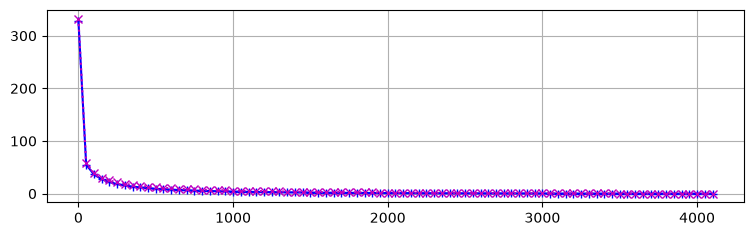

In [ ]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

#Xtr = x_train.reshape(len(x_train), -1) / 255.0
#Xval = x_val.reshape(len(x_val), -1) / 255.0
#Xte = x_test.reshape(len(x_test), -1) / 255.0
#print(Xtr.shape)

max_K = np.min(Xtr.shape);print(f"max_K: {max_K}")
pca = PCA(n_components=max_K).fit(Xtr)
Ztr = pca.transform(Xtr); Zval = pca.transform(Xval)
Ks = np.array([k for k in range(0, max_K + 50, 50)])
L_train = np.empty_like(Ks, dtype=float); L_test = np.empty_like(Ks, dtype=float)
for i, K in enumerate(Ks):
    Z_train_K = Ztr.copy(); Z_train_K[:, K:] = 0.0; hX_train = pca.inverse_transform(Z_train_K)
    L_train[i] = np.square(Xtr - hX_train).sum(axis=1).mean()
    Zval_K = Zval.copy(); Zval_K[:, K:] = 0.0; hX_val = pca.inverse_transform(Zval_K)
    L_test[i] = np.square(Xval - hX_val).sum(axis=1).mean()
plt.figure(figsize=(9, 2.5)); plt.grid(True); plt.plot(Ks, L_train, '+-b', Ks, L_test, 'x:m');


**Comentario:** La curva de error de reconstrucción cae muy rápido hasta K≈150-200, aplanándose después casi a cero hacia K≈1500-2000. Esto dice que casi toda la información relevante de la imagen como la forma general del órgano y contraste tejido/fondo está concentrada en pocos cientos de componentes, y el resto son matices cada vez más finos que casi no aportan a la reconstrucción visual.

### Eigen-imagenes y reconstrucción

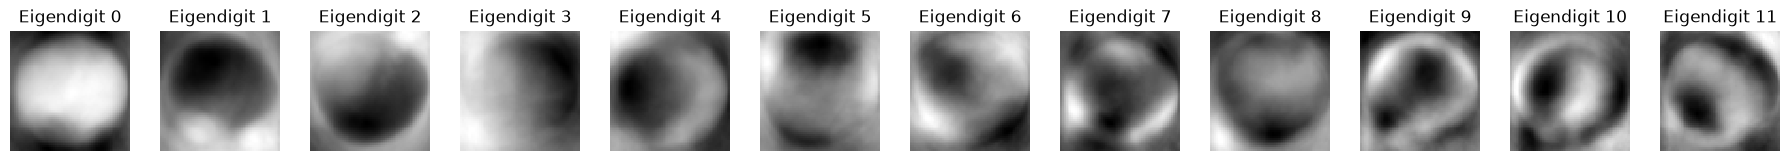

In [5]:
K = 100; pca = PCA(n_components=K).fit(Xtr); nrows, ncols = 1, 12
fig, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(18, 18*nrows/ncols), constrained_layout=True)
for i in range(min(K, nrows * ncols)):
    ax = axs.flat[i]; ax.set_axis_off(); ax.set_title(f"Eigendigit {i}")
    ax.imshow(pca.components_[i, :].reshape((64, 64)), cmap=plt.cm.gray, interpolation="none")

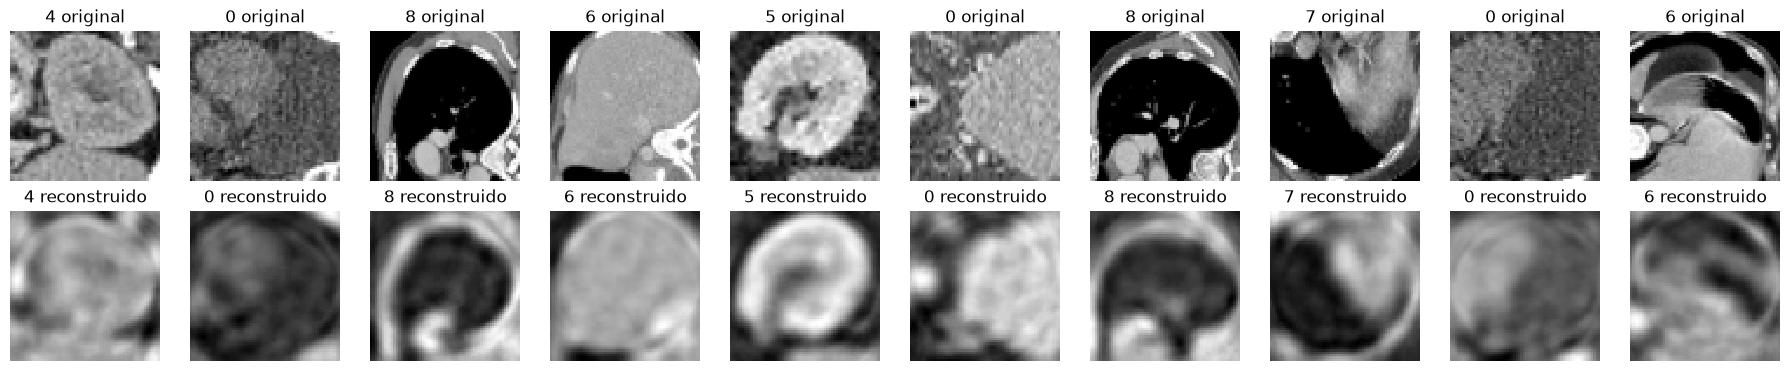

In [6]:
ncols = 10; Z_test = pca.transform(Xte[:ncols]); hX_test = pca.inverse_transform(Z_test)
fig, axs = plt.subplots(nrows=2, ncols=10, figsize=(18, 18*2/ncols), constrained_layout=True)
for i in range(ncols):
    ax = axs.flat[i]; ax.set_axis_off(); ax.set_title(f"{y_test[i]} original")
    ax.imshow(Xte[i, :].reshape((64, 64)), cmap=plt.cm.gray, interpolation="none")
    ax = axs.flat[ncols + i]; ax.set_axis_off(); ax.set_title(f"{y_test[i]} reconstruido")
    ax.imshow(hX_test[i, :].reshape((64, 64)), cmap=plt.cm.gray, interpolation="none")

**Comentario:** Las reconstrucciones con K=100 confirman que se recupera bien la forma y el contraste global del órgano, pero se pierde toda la textura interna original, que queda borrosa, la cual es reconstruida con mayor número de componentes.

### Precisión de Regresión Logística: estudio en función de K

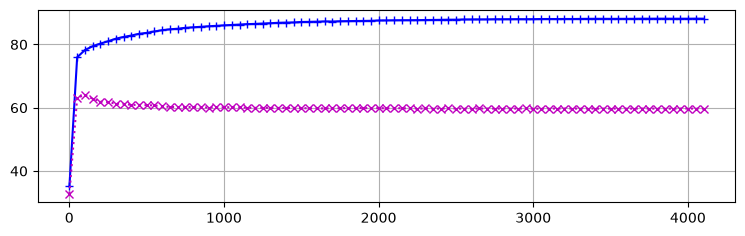

In [9]:
from sklearn.linear_model import LogisticRegression
max_K = np.min(Xtr.shape); pca = PCA(n_components=max_K).fit(Xtr)
Z_train = pca.transform(Xtr); Z_test = pca.transform(Xte)
Ks = np.array([k for k in range(1, max_K + 50, 50)])
acc_train = np.empty_like(Ks, dtype=float); acc_test = np.empty_like(Ks, dtype=float)
for i, K in enumerate(Ks):
    clf = LogisticRegression(C=0.1, max_iter=1000).fit(Z_train[:, :K], y_train)
    acc_train[i] = clf.score(Z_train[:, :K], y_train)
    acc_test[i] = clf.score(Z_test[:, :K], y_test)
plt.figure(figsize=(9, 2.5)); plt.grid(True)
plt.plot(Ks, 100. * acc_train, '+-b', Ks, 100. * acc_test, 'x:m');

**Comentario:** En cuanto a la curva de accuracy de la regresión logística frente a K muestra que el test sube muy rápido hasta K≈50-100, toca su máximo alrededor de K≈100-150 con un 64-65% de acierto, y a partir de ahí decrece de forma constante hasta estabilizarse en torno al 60% usando todas las 4096 componentes, mientras que el train sigue subiendo sin parar (78%->88%). 

Esto demuestra sobreajuste, pasado ese punto con K > 150, las componentes adicionales aportan detalles propios de las imágenes de entrenamiento que no generalizan a imágenes nuevas. De este modo, de aquí en adelante, usaremos un rango de K $\in$ [50, 200] que será nuestra elección para seguir trabajando.

### Matriz de confusión

K con mayor accuracy de test: 100  (acc_test = 0.6397)


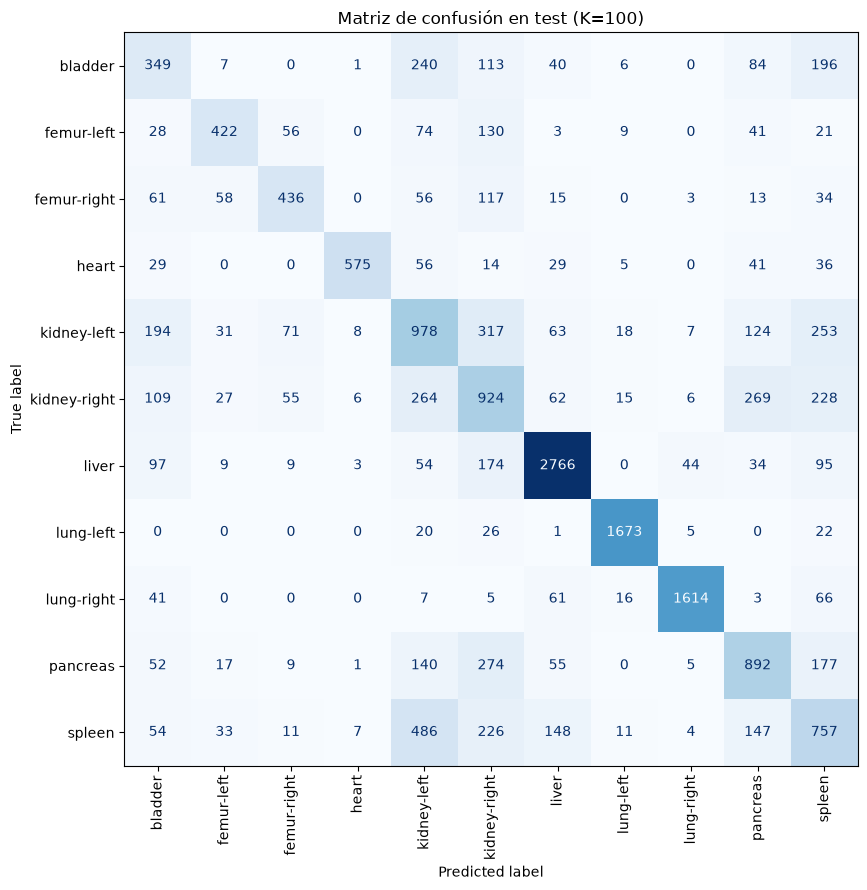


Acierto global: 64.0%

Clase           Acierto (%)    N (test)
lung-left             95.8%        1747
lung-right            89.0%        1813
liver                 84.2%        3285
heart                 73.2%         785
pancreas              55.0%        1622
femur-right           55.0%         793
femur-left            53.8%         784
kidney-left           47.4%        2064
kidney-right          47.0%        1965
spleen                40.2%        1884
bladder               33.7%        1036


In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

K_best = Ks[np.argmax(acc_test)] -1  # usamos el mejor K según accuracy de test
print(f"K con mayor accuracy de test: {K_best}  (acc_test = {acc_test.max():.4f})")

# Reentrenamos solo con ese K subimos max_iter
#  para que converja y no añada ruido a la comparación
clf_best = LogisticRegression(C=0.1, max_iter=5000).fit(Z_train[:, :K_best], y_train)
y_pred = clf_best.predict(Z_test[:, :K_best])

labels = ['bladder', 'femur-left', 'femur-right', 'heart', 'kidney-left',
          'kidney-right', 'liver', 'lung-left', 'lung-right', 'pancreas', 'spleen']

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=labels)

fig, ax = plt.subplots(figsize=(9, 9))
disp.plot(ax=ax, xticks_rotation=90, cmap='Blues', colorbar=False)
plt.title(f'Matriz de confusión en test (K={K_best})')
plt.tight_layout()
plt.show()

acc_per_class = 100 * cm.diagonal() / cm.sum(axis=1)

print(f"\nAcierto global: {100 * cm.diagonal().sum() / cm.sum():.1f}%\n")
print(f"{'Clase':<15}{'Acierto (%)':>12}{'N (test)':>12}")
for label, acc, n in sorted(zip(labels, acc_per_class, cm.sum(axis=1)),
                             key=lambda x: x[1], reverse=True):
    print(f"{label:<15}{acc:>11.1f}%{n:>12d}")

**Comentario:** La matriz de confusión en test con K=100 con un acierto global del 64% reparte los errores de forma muy desigual entre clases. Hígado, pulmón izquierdo y pulmón derecho se clasifican muy bien con 84%, 96% y 89% de acierto respectivamente, ya que son estructuras grandes, con contraste y forma muy distintivos. El problema se concentra en el grupo de órganos abdominales pequeños y de forma parecida: riñón izquierdo y riñón derecho se confunden mucho entre sí y ambos con vejiga, bazo y páncreas, la vejiga se confunde sobre todo con los riñones y el bazo, y el bazo se confunde muchísimo con el riñón izquierdo (487 casos) y el derecho.

Esta primera matriz nos deja ver que clases van a ser más complicadas de clasificar de forma general. Así que nuestro esfuerzo se centrará en mejorar su acierto en los diferentes modelos que probemos.

## 4. Análisis discriminante (TL03)

Aplicación de QDA y QDA sobre las proyecciones PCA, comparando su precisión en función de K y los parámetros `reg_param` de QDA y `tol` de LDA.

EN de esta sección:
- Ajustar LDA/QDA sobre las componentes PCA elegidas.
- Comparar precisión entre QDA y LDA.
- Comentar la frontera de decisión lineal (LDA) frente a la cuadrática (QDA) en este problema de 11 clases.

In [11]:
from sklearn.model_selection import ShuffleSplit


K = 400; pca = PCA(n_components=K); X_train = pca.fit_transform(Xtr); X_test = pca.transform(Xte)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

Ks = np.arange(50, 401, 10)   # 50, 60, 70, ..., 400
splitter = ShuffleSplit(n_splits=2, test_size=0.1, random_state=23)

(34561, 400) (34561,) (17778, 400) (17778,)


loguniform, distribucion que seguiremos para muestrear valores de reg_param

In [12]:
from scipy.stats import loguniform; loguniform(1e-4, 1e-1).rvs(5)


array([0.00056285, 0.0005592 , 0.07898943, 0.00053787, 0.01200386])

### QDA

In [13]:
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.model_selection import RandomizedSearchCV
import time; start = time.time()
import matplotlib.pyplot as plt


acc_qda      = np.empty_like(Ks, dtype=float)
best_qda_reg = np.empty_like(Ks, dtype=float)

for i, K in enumerate(Ks):
    Xtrain, Xtest = X_train[:, :K], X_test[:, :K] # nos quedamos con las K primeras componentes PCA

    clf_qda = QuadraticDiscriminantAnalysis()
    G_qda = {'reg_param': loguniform(1e-4, 1e-1)}
    RS_qda = RandomizedSearchCV(clf_qda, G_qda, n_iter=10, scoring='accuracy',
                                 n_jobs=-1, cv=splitter, pre_dispatch=32)
    RS_qda.fit(Xtrain, y_train)
    acc_qda[i] = RS_qda.score(Xtest, y_test)
    best_qda_reg[i] = RS_qda.best_params_['reg_param']

    #print(f"K={K:>3}  QDA={acc_qda[i]:.2%}  (reg_param={best_qda_reg[i]:.4f})")

print('Tiempo total (hh:mm:ss):', time.strftime('%H:%M:%S', time.gmtime(time.time() - start)))



Tiempo total (hh:mm:ss): 00:11:46


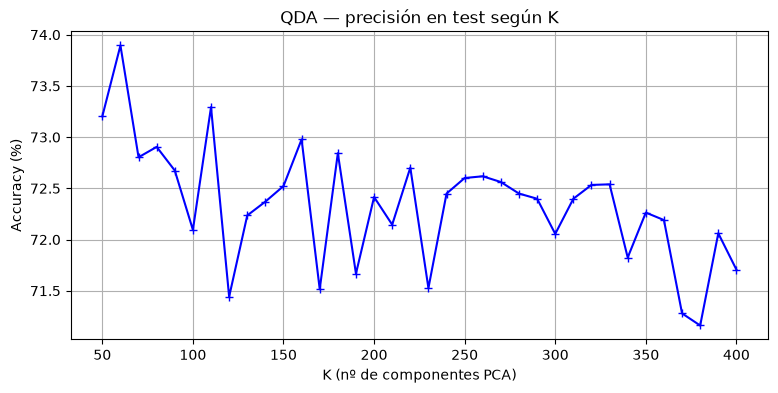

In [14]:
plt.figure(figsize=(9, 4))
plt.plot(Ks, 100 * acc_qda, '+-b')
plt.xlabel('K (nº de componentes PCA)'); plt.ylabel('Accuracy (%)')
plt.grid(True); plt.title('QDA — precisión en test según K')
plt.show()

In [15]:
print(f"Mejor precisión: {100 * acc_qda.max():.2f}% con K={Ks[acc_qda.argmax()]} y reg_param={best_qda_reg[acc_qda.argmax()]:.4f}")

Mejor precisión: 73.89% con K=60 y reg_param=0.0966


### LDA

In [16]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

acc_lda      = np.empty_like(Ks, dtype=float)
best_lda_tol = np.empty_like(Ks, dtype=float)

for i, K in enumerate(Ks):
    Xtrain, Xtest = X_train[:, :K], X_test[:, :K]

    clf_lda = LinearDiscriminantAnalysis()
    G_lda = {'tol': loguniform(1e-4, 1e-1)}
    RS_lda = RandomizedSearchCV(clf_lda, G_lda, n_iter=10, scoring='accuracy',
                                 n_jobs=-1, cv=splitter, pre_dispatch=8)
    RS_lda.fit(Xtrain, y_train)
    acc_lda[i] = RS_lda.score(Xtest, y_test)
    best_lda_tol[i] = RS_lda.best_params_['tol']

    #print(f"K={K:>3}  LDA={acc_lda[i]:.2%}  (tol={best_lda_tol[i]:.2e})")

print('Tiempo total (hh:mm:ss):', time.strftime('%H:%M:%S', time.gmtime(time.time() - start)))



Tiempo total (hh:mm:ss): 00:24:46


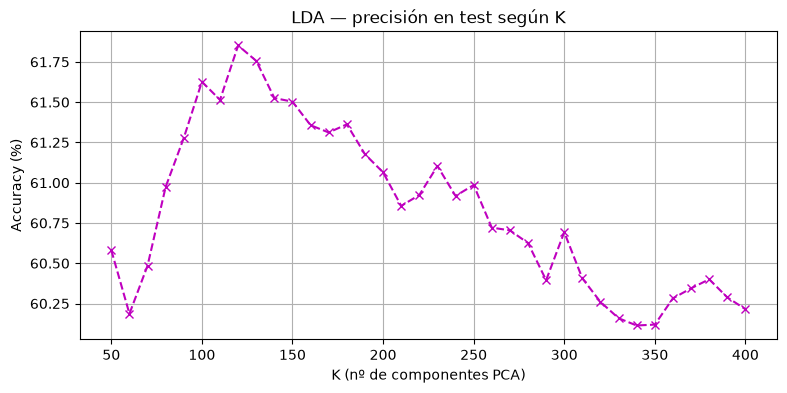

Mejor precisión: 61.85% con K=120 y tol=2.80e-03


In [17]:
plt.figure(figsize=(9, 4))
plt.plot(Ks, 100 * acc_lda, 'x--m')
plt.xlabel('K (nº de componentes PCA)'); plt.ylabel('Accuracy (%)')
plt.grid(True); plt.title('LDA — precisión en test según K')
plt.show()

print(f"Mejor precisión: {100 * acc_lda.max():.2f}% con K={Ks[acc_lda.argmax()]} y tol={best_lda_tol[acc_lda.argmax()]:.2e}")

**Comentario:** QDA supera a LDA en este dataset: 73.89% de precisión máxima (K=60) frente a 61.85% de LDA (K=120). Esto indica que cada órgano tiene su propia dispersión y forma, algo que solo QDA, al modelar una covarianza distinta por clase, es capaz de aprovechar.

Al no poder curvar sus fronteras, LDA fuerza una separación recta entre clases que en realidad se solapan de forma no lineal, y ahí es donde pierde precisión frente a QDA.

## 5. Regresión logística (TL04)

Regresión logística para la multi-clasificación e ingeniería de características, con ajuste de hiperparámetros mediante `RandomizedSearchCV`.

En esta sección:
- Ajuste de hiperparámetros sobre el espacio `G = {'tol': ..., 'C': ..., 'fit_intercept': ...}` y sobre el espacio `Q = {'tol': ..., 'C': ..., 'fit_intercept': ..., 'degree': ..., 'interaction_only': ...}` para regresión logística con ingeniería de características.
- Precisión final en test con los mejores hiperparámetros.

In [7]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression


K = 100; pca = PCA(n_components=K); X_train = pca.fit_transform(Xtr); X_test = pca.transform(Xte)

param_grid_simple = {
    'C': [0.01, 0.1, 1.0, 10.0],
    'tol': [1e-4, 1e-3, 1e-2],
    'fit_intercept': [True, False],
    'solver': ['lbfgs'],
}

grid_simple = GridSearchCV(
    estimator=LogisticRegression(max_iter=1000),
    param_grid=param_grid_simple,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
)

grid_simple.fit(X_train, y_train)

best_model_simple = grid_simple.best_estimator_
acc_simple_test = best_model_simple.score(X_test, y_test)

print('Resultados sin ingeniería de características: ')
print(f'Mejores hiperparámetros: {grid_simple.best_params_}')
print(f'Precisión en (Train/Val): {grid_simple.best_score_:.2%}')
print(f'Precisión en Test: {acc_simple_test:.2%}\n')


# Con ingeniería de características
pipeline_poly = make_pipeline(
    StandardScaler(), PolynomialFeatures(), LogisticRegression(max_iter=1000)
)

param_grid_poly = {
    'polynomialfeatures__degree': [1, 2],
    'polynomialfeatures__interaction_only': [False, True],
    'polynomialfeatures__include_bias': [False],
    'logisticregression__C': [0.1, 1.0, 10.0],
    'logisticregression__tol': [1e-4, 1e-3],
    'logisticregression__fit_intercept': [True, False],
    'logisticregression__solver': ['lbfgs'],
}

grid_poly = GridSearchCV(
    estimator=pipeline_poly,
    param_grid=param_grid_poly,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
)

grid_poly.fit(X_train, y_train)

best_model_poly = grid_poly.best_estimator_
acc_poly_test = best_model_poly.score(X_test, y_test)

print('Resultados con ingeniería de características: ')
print(f'Mejores hiperparámetros: {grid_poly.best_params_}')
print(f'Precisión en (Train/Val): {grid_poly.best_score_:.2%}')
print(f'Precisión en Test: {acc_poly_test:.2%}\n')




Resultados sin ingeniería de características: 
Mejores hiperparámetros: {'C': 1.0, 'fit_intercept': True, 'solver': 'lbfgs', 'tol': 0.0001}
Precisión en (Train/Val): 77.25%
Precisión en Test: 63.93%

Resultados con ingeniería de características: 
Mejores hiperparámetros: {'logisticregression__C': 0.1, 'logisticregression__fit_intercept': True, 'logisticregression__solver': 'lbfgs', 'logisticregression__tol': 0.0001, 'polynomialfeatures__degree': 2, 'polynomialfeatures__include_bias': False, 'polynomialfeatures__interaction_only': False}
Precisión en (Train/Val): 98.41%
Precisión en Test: 69.69%



**Comentario:** Ajustar los hiperparámetros en el modelo lineal no ha aportado nada: Al inicio del cuaderno se utilizó el modelo de regresión logística con C=0.1 para ajustar y determinar que K (componentes) para aplicar sobre distintos modelos, y obtuve 64.0% y con C=1.0 63.93%, así que el techo de la regresión logística lineal sobre 100 componentes PCA está en torno al 64%. La mejora real viene de añadir características polinómicas de grado 2, que suben el test a 69.10%, porque permiten trazar fronteras curvas, igual que la ventaja de QDA sobre LDA. Aun así, se queda por debajo de QDA (73.65%).

Las cifras de Train/Val (77.25% y 98.38%) son superiores a las de test (63.93% y 69.10%). Un 98% con unas 5000 características indica que el modelo casi memoriza train. Por eso la cifra fiable es la de test.

## 6. Regresión lineal (TL05)

En un problema de clasificación como OrganAMNIST la regresión lineal no es el modelo natural, dejando constancia de por qué no es adecuado como modelo para clasificar este dataset.

Tareas de esta sección:
- Plantear el experimento de regresión lineal sin y con ingeriería visual.
- Comparar sus limitaciones.

In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

K = 100
pca = PCA(n_components=K)
X_train = pca.fit_transform(Xtr)
X_test  = pca.transform(Xte)

Regresión lineal sin ingeniería de características

R2       -> train: 0.28  test: 0.18
Accuracy -> train: 25.25%  test: 21.72%


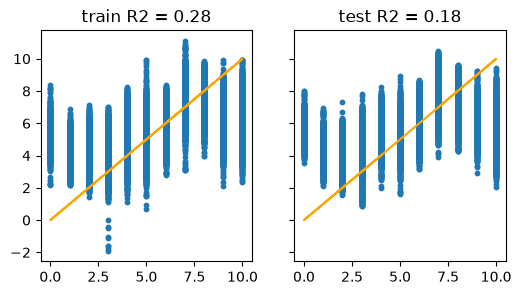

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, accuracy_score
import matplotlib.pyplot as plt

linreg = LinearRegression().fit(X_train, y_train)
y_train_pred = linreg.predict(X_train); y_test_pred = linreg.predict(X_test)
r2_train = r2_score(y_train, y_train_pred); r2_test = r2_score(y_test, y_test_pred)

# Redondeo a la clase de órgano más cercana (0-10) para poder medir accuracy
y_train_pred_cls = np.clip(np.round(y_train_pred), 0, 10).astype(int)
y_test_pred_cls  = np.clip(np.round(y_test_pred), 0, 10).astype(int)
acc_train = accuracy_score(y_train.astype(int), y_train_pred_cls)
acc_test  = accuracy_score(y_test.astype(int), y_test_pred_cls)

print(f'R2       -> train: {r2_train:.2f}  test: {r2_test:.2f}')
print(f'Accuracy -> train: {acc_train:.2%}  test: {acc_test:.2%}')

fig, axs = plt.subplots(1, 2, figsize=(6, 3), sharey='all')
ax = axs[0]; ax.set_title(f'train R2 = {r2_train:.2f}')
ax.scatter(y_train, y_train_pred, s=10); ax.plot(y_train, y_train, color='orange')
ax = axs[1]; ax.set_title(f'test R2 = {r2_test:.2f}')
ax.scatter(y_test, y_test_pred, s=10); ax.plot(y_test, y_test, color='orange');

Regresión lineal con ingeniería de características

R2       -> train: 0.82  test: -0.14
Accuracy -> train: 43.36%  test: 15.74%


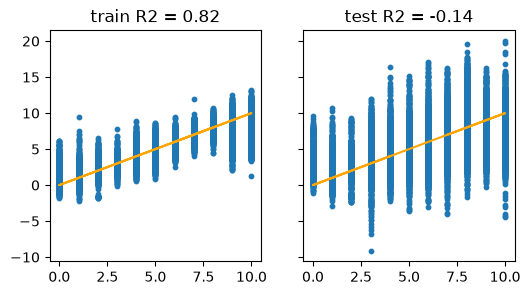

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly  = poly.transform(X_test)
linreg_poly = LinearRegression().fit(X_train_poly, y_train)
y_train_pred = linreg_poly.predict(X_train_poly); y_test_pred = linreg_poly.predict(X_test_poly)
r2_train_poly = r2_score(y_train, y_train_pred); r2_test_poly = r2_score(y_test, y_test_pred)

y_train_pred_cls = np.clip(np.round(y_train_pred), 0, 10).astype(int)
y_test_pred_cls  = np.clip(np.round(y_test_pred), 0, 10).astype(int)
acc_train_poly = accuracy_score(y_train.astype(int), y_train_pred_cls)
acc_test_poly  = accuracy_score(y_test.astype(int), y_test_pred_cls)

print(f'R2       -> train: {r2_train_poly:.2f}  test: {r2_test_poly:.2f}')
print(f'Accuracy -> train: {acc_train_poly:.2%}  test: {acc_test_poly:.2%}')

fig, axs = plt.subplots(1, 2, figsize=(6, 3), sharey='all')
ax = axs[0]; ax.set_title(f'train R2 = {r2_train_poly:.2f}')
ax.scatter(y_train, y_train_pred, s=10); ax.plot(y_train, y_train, color='orange')
ax = axs[1]; ax.set_title(f'test R2 = {r2_test_poly:.2f}')
ax.scatter(y_test, y_test_pred, s=10); ax.plot(y_test, y_test, color='orange');

In [12]:
print(f'R2:       sin ingeniería de caracterñisticas {r2_test:.2f},  con ingeniería de características {r2_test_poly:.2f}  '
      f'(train: sin {r2_train:.2f}, con {r2_train_poly:.2f})')
print(f'Accuracy: sin ingeniería de caracterñisticas {acc_test:.2%}  con ingeniería de caracterñisticas {acc_test_poly:.2%}  '
      f'(train: sin {acc_train:.2%}, con {acc_train_poly:.2%})')

R2:       sin ingeniería de caracterñisticas 0.18,  con ingeniería de características -0.14  (train: sin 0.28, con 0.82)
Accuracy: sin ingeniería de caracterñisticas 21.72%  con ingeniería de caracterñisticas 15.74%  (train: sin 25.25%, con 43.36%)


**Comentario:** La regresión lineal confirma que no es el modelo adecuado para este problema. Sin ingeniería de características apenas llega a R2=0.18 en test y 21.72% de accuracy, ligeramente mejor que adivinar al azar (≈9% con 11 clases) pero muy lejos de un clasificador real. Al añadir polinomios de grado 2 el modelo se sobreajusta de forma evidente, el R2 de train sube a 0.82 pero el de test cae a -0.14, y el accuracy de test baja de 21.72% a 15.74% pese a que en train sube a 43.36%.

Comparado con QDA (73.65%) o la regresión logística (~64-69% según configuración), la diferencia es enorme. Tiene sentido, ya que tratar las etiquetas de órgano como si fueran una magnitud continua no captura que son categorías sin orden real entre sí, así que ni la versión lineal ni la polinómica tienen forma de generalizar bien. Esto demuestra que este dataset funciona mejor con un clasificador que con un regresor.

## 7. Redes neuronales con PyTorch (TL06)

Diseño y entrenamiento desde cero de una red neuronal (CNN sencilla) con PyTorch sobre OrganAMNIST, sin pesos preentrenados, como paso previo al uso de modelos preentrenados en TL07.

En esta sección:
- Definición del `Dataset`/`DataLoader` a partir de los arrays `numpy` cargados en la Sección 2.
- Arquitectura de MLP y CNN, función de pérdida y optimizador.
- Curvas de entrenamiento/validación (pérdida y precisión) y precisión final en test.

Creamos un Dataset personalizado a partir de los arrays Numpy ya cargados, y los envolvemos con DataLoader para entrenar por batches

In [3]:
# Cargamos los datos de OrganAMNIST en formato PyTorch
data = np.load('../data/organamnist_64.npz')
X_train_img = data['train_images'].astype(np.float32).reshape(-1, 1, 64, 64) / 255.0
X_test_img  = data['test_images'].astype(np.float32).reshape(-1, 1, 64, 64) / 255.0
X_val_img   = data['val_images'].astype(np.float32).reshape(-1, 1, 64, 64) / 255.0
y_train = data['train_labels'].ravel().astype(np.int64)
y_test  = data['test_labels'].ravel().astype(np.int64)
y_val   = data['val_labels'].ravel().astype(np.int64)

print(X_train_img.shape, X_test_img.shape, X_val_img.shape)

(34561, 1, 64, 64) (17778, 1, 64, 64) (6491, 1, 64, 64)


In [4]:
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

class OrganAMNISTDataset(Dataset):
    def __init__(self, images, labels):
        self.images = torch.from_numpy(images)
        self.labels = torch.from_numpy(labels)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        return self.images[idx], self.labels[idx]

train_data = OrganAMNISTDataset(X_train_img, y_train)
val_data   = OrganAMNISTDataset(X_val_img, y_val)
test_data  = OrganAMNISTDataset(X_test_img, y_test)

batch_size = 64
train_dataloader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
val_dataloader   = DataLoader(val_data, batch_size=batch_size)
test_dataloader  = DataLoader(test_data, batch_size=batch_size)

X, y = next(iter(train_dataloader))
n_classes = len(np.unique(y_train))
print(f"Shape de X [N, C, H, W]: {X.shape}")
print(f"Shape de y: {y.shape} {y.dtype}")



Shape de X [N, C, H, W]: torch.Size([64, 1, 64, 64])
Shape de y: torch.Size([64]) torch.int64


### Dispositivo de entramiento

In [5]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Usando dispositivo: {device}")


Usando dispositivo: cpu


### MLP
Aplanamos la imagen 64×64 a un vector de 4096 píxeles y lo pasamos por dos capas ocultas con ReLU hasta una salida de 11 logits (uno por órgano).

In [8]:
from torch import nn

class MLP(nn.Module):
    def __init__(self, n_classes=11):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(64 * 64, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, n_classes)
        )
    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

mlp = MLP(n_classes).to(device)
print(mlp)


MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=4096, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=11, bias=True)
  )
)


### Funciones de entranamiento y test
Devolvemos pérdida y accuracy medias por época

In [6]:
def train_loop(dataloader, model, loss_fn, optimizer):
    model.train()
    size = len(dataloader.dataset)
    total_loss, correct = 0.0, 0
    for X, y in dataloader:
        X, y = X.to(device), y.to(device)
        pred = model(X)
        loss = loss_fn(pred, y)
        loss.backward(); optimizer.step(); optimizer.zero_grad()
        total_loss += loss.item() * len(X)
        correct += (pred.argmax(1) == y).type(torch.float).sum().item()
    return total_loss / size, correct / size

def test_loop(dataloader, model, loss_fn):
    model.eval()
    size = len(dataloader.dataset)
    total_loss, correct = 0.0, 0
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            total_loss += loss_fn(pred, y).item() * len(X)
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()
    return total_loss / size, correct / size


In [10]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(mlp.parameters(), lr=1e-3)

epochs = 10
history_mlp = []
for t in range(epochs):
    train_loss, train_acc = train_loop(train_dataloader, mlp, loss_fn, optimizer)
    val_loss, val_acc = test_loop(val_dataloader, mlp, loss_fn)
    history_mlp.append((train_loss, train_acc, val_loss, val_acc))
    print(f"Epoch {t+1}: train loss {train_loss:.4f} acc {train_acc:.2%} | val loss {val_loss:.4f} acc {val_acc:.2%}")

test_loss_mlp, test_acc_mlp = test_loop(test_dataloader, mlp, loss_fn)
print(f"\nMLP — Test loss: {test_loss_mlp:.4f}  Test accuracy: {test_acc_mlp:.2%}")


Epoch 1: train loss 0.9042 acc 68.48% | val loss 0.5229 acc 84.21%
Epoch 2: train loss 0.5592 acc 80.26% | val loss 0.7185 acc 77.62%
Epoch 3: train loss 0.4728 acc 83.53% | val loss 0.4226 acc 88.88%
Epoch 4: train loss 0.3666 acc 87.42% | val loss 0.4732 acc 87.72%
Epoch 5: train loss 0.3103 acc 89.57% | val loss 0.5395 acc 87.80%
Epoch 6: train loss 0.2779 acc 90.65% | val loss 0.4475 acc 90.54%
Epoch 7: train loss 0.2267 acc 92.56% | val loss 0.4686 acc 89.83%
Epoch 8: train loss 0.1967 acc 93.50% | val loss 0.8656 acc 80.71%
Epoch 9: train loss 0.2213 acc 93.10% | val loss 0.4311 acc 89.45%
Epoch 10: train loss 0.1650 acc 94.72% | val loss 0.4918 acc 90.54%

MLP — Test loss: 1.1889  Test accuracy: 71.44%


### CNN
Adaptación de LeNet con ReLu a imágenes de 64x64 y 1 canal, con salida de 11 clases. Con dos convoluciones 5x5 y max-pooling 2x2 que van reduciendo la imagen hasta llegar a las capas densas

In [11]:
import torch.nn.functional as F

class LeNetOrgan(nn.Module):
    def __init__(self, n_classes=11):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=6, kernel_size=5)
        self.conv2 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5)
        self.fc1 = nn.Linear(16 * 13 * 13, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, n_classes)
    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), kernel_size=2)
        x = F.max_pool2d(F.relu(self.conv2(x)), kernel_size=2)
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

cnn = LeNetOrgan(n_classes).to(device)
print(cnn)


LeNetOrgan(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=2704, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=11, bias=True)
)


In [22]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(cnn.parameters(), lr=1e-3)

epochs = 10
history_cnn = []
for t in range(epochs):
    train_loss, train_acc = train_loop(train_dataloader, cnn, loss_fn, optimizer)
    val_loss, val_acc = test_loop(val_dataloader, cnn, loss_fn)
    history_cnn.append((train_loss, train_acc, val_loss, val_acc))
    print(f"Epoch {t+1}: train loss {train_loss:.4f} acc {train_acc:.2%} | val loss {val_loss:.4f} acc {val_acc:.2%}")

test_loss_cnn, test_acc_cnn = test_loop(test_dataloader, cnn, loss_fn)
print(f"\nCNN (LeNet) — Test loss: {test_loss_cnn:.4f}  Test accuracy: {test_acc_cnn:.2%}")


Epoch 1: train loss 0.0400 acc 98.68% | val loss 0.2085 acc 95.81%
Epoch 2: train loss 0.0307 acc 98.97% | val loss 0.2490 acc 94.44%
Epoch 3: train loss 0.0358 acc 98.81% | val loss 0.2293 acc 95.13%
Epoch 4: train loss 0.0233 acc 99.22% | val loss 0.2130 acc 95.16%
Epoch 5: train loss 0.0239 acc 99.27% | val loss 0.2368 acc 95.72%
Epoch 6: train loss 0.0231 acc 99.15% | val loss 0.1705 acc 96.23%
Epoch 7: train loss 0.0207 acc 99.31% | val loss 0.2509 acc 95.13%
Epoch 8: train loss 0.0222 acc 99.29% | val loss 0.1887 acc 96.33%
Epoch 9: train loss 0.0208 acc 99.35% | val loss 0.2980 acc 94.08%
Epoch 10: train loss 0.0125 acc 99.60% | val loss 0.3054 acc 94.85%

CNN (LeNet) — Test loss: 1.1011  Test accuracy: 83.56%


### CNN 2
Porbamos otra cnn añadiendo elementos vistos durante la asignatura. CNN2 usa tres convoluciones de 3×3 con 32, 64 y 128 filtros. Cada una lleva BatchNorm, ReLU y max-pooling, así que la imagen pasa de 64 a 32, a 16 y a 8 de lado. En lugar de aplanar, aplico Global Average Pooling, después Dropout de 0,3 y una única capa lineal de 128 a 11

In [25]:
class CNN2(nn.Module):
    def __init__(self, n_classes=11):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),                                              # 64x64 -> 32x32
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2),                                              # 32x32 -> 16x16
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.MaxPool2d(2),                                              # 16x16 -> 8x8
        )
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),   # Global Average Pooling: 128x8x8 -> 128x1x1
            nn.Flatten(),
            nn.Dropout(p=0.3),
            nn.Linear(128, n_classes)
        )
    def forward(self, x):
        x = self.body(x)
        x = self.head(x)
        return x

cnn2 = CNN2(n_classes).to(device)
print(cnn2)

CNN2(
  (body): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head): Sequential(
    (0): AdaptiveAvgPool2d(output_size=1)
    (1): Flatten(start_dim=1, end_dim=-1)
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=

In [26]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(cnn2.parameters(), lr=1e-3)

epochs = 10
history_cnn2 = []
for t in range(epochs):
    train_loss, train_acc = train_loop(train_dataloader, cnn2, loss_fn, optimizer)
    val_loss, val_acc = test_loop(val_dataloader, cnn2, loss_fn)
    history_cnn2.append((train_loss, train_acc, val_loss, val_acc))
    print(f"Epoch {t+1}: train loss {train_loss:.4f} acc {train_acc:.2%} | val loss {val_loss:.4f} acc {val_acc:.2%}")

test_loss_cnn2, test_acc_cnn2 = test_loop(test_dataloader, cnn2, loss_fn)
print(f"\nCNNModerna — Test loss: {test_loss_cnn2:.4f}  Test accuracy: {test_acc_cnn2:.2%}")

Epoch 1: train loss 0.6873 acc 77.01% | val loss 0.6947 acc 75.77%
Epoch 2: train loss 0.3632 acc 87.50% | val loss 4.3408 acc 51.38%
Epoch 3: train loss 0.2896 acc 89.99% | val loss 0.5567 acc 80.70%
Epoch 4: train loss 0.2499 acc 91.35% | val loss 0.3345 acc 88.52%
Epoch 5: train loss 0.2255 acc 92.08% | val loss 0.4725 acc 83.65%
Epoch 6: train loss 0.2020 acc 92.93% | val loss 0.1631 acc 94.38%
Epoch 7: train loss 0.1877 acc 93.33% | val loss 0.6230 acc 80.59%
Epoch 8: train loss 0.1708 acc 93.95% | val loss 0.1135 acc 96.60%
Epoch 9: train loss 0.1643 acc 94.34% | val loss 0.3306 acc 86.47%
Epoch 10: train loss 0.1629 acc 94.41% | val loss 0.1860 acc 93.50%

CNNModerna — Test loss: 0.3252  Test accuracy: 88.83%


### Resultados de las redes neuronales

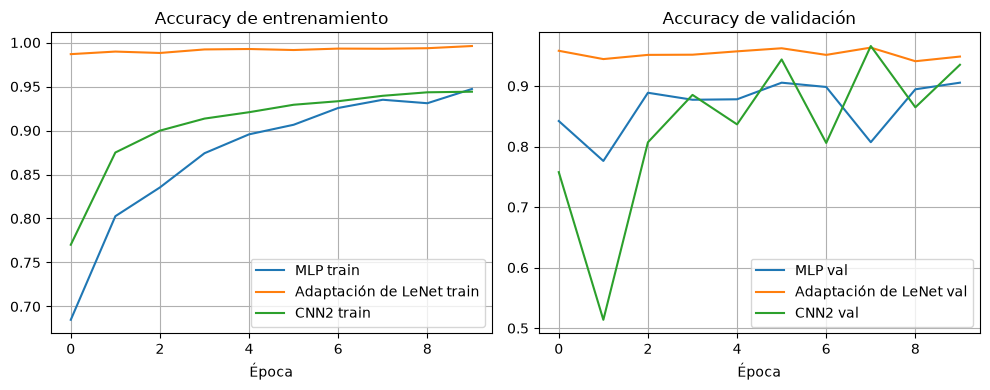

In [31]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for history, label in [(history_mlp, 'MLP'), (history_cnn, 'Adaptación de LeNet'), (history_cnn2, 'CNN2')]:
    train_accs = [h[1] for h in history]
    val_accs = [h[3] for h in history]
    axs[0].plot(train_accs, label=f'{label} train')
    axs[1].plot(val_accs, label=f'{label} val')
axs[0].set_title('Accuracy de entrenamiento'); axs[0].set_xlabel('Época'); axs[0].legend(); axs[0].grid(True)
axs[1].set_title('Accuracy de validación'); axs[1].set_xlabel('Época'); axs[1].legend(); axs[1].grid(True)
plt.tight_layout(); plt.show()

In [30]:
print("Comparación de accuracy en test:")
print(f"  Regresión logística (grado 2, K=100): 69.69%")
print(f"  QDA (K=70):                           73.89%")
print(f"  LDA (K=120):                          61.85%")
print(f"  MLP:                                  {test_acc_mlp:.2%}")
print(f"  CNN (LeNet):                          {test_acc_cnn:.2%}")
print(f"  CNN (CNN2):                           {test_acc_cnn2:.2%}")

Comparación de accuracy en test:
  Regresión logística (grado 2, K=100): 69.69%
  QDA (K=70):                           73.89%
  LDA (K=120):                          61.85%
  MLP:                                  71.44%
  CNN (LeNet):                          83.56%
  CNN (CNN2):                           88.83%


**Comentario:** Las dos CNN superan claramente a todo lo anterior: CNN2 (88.83%) y la modificación de LeNet (83.56%) están muy por encima de QDA (73.89%), regresión logística (69.69%) y LDA (61.85%). Una convolución explota la estructura espacial de la imagen, algo que ni PCA+modelo lineal/cuadrático ni un MLP sobre píxeles aplanados pueden aprovechar.

La modificación de LeNet converge rápido y de forma estable, ya empieza en ~99% de train y ~96% de validación en la época 0, y apenas se mueve después.

CNN2 es justo lo contrario, su validación es muy ruidosa, con una caída brusca a 0.52 en la época 1 antes de recuperarse y oscilar bastante el resto del entrenamiento. Es coherente con tener más canales y BatchNorm, que al principio del entrenamiento desestabiliza la validación. Pese al ruido, termina aprendiendo más que LeNet, train y test acaban más altos (88.83% en test), lo que puede sugerir que los canales extra y el Global Average Pooling sí le dan margen para captar patrones que LeNet.

El MLP es la red que peor generaliza de las tres (71.44%), necesita más épocas para subir el train (empieza en 0.69 y sube lento) y su validación, aunque mejora, se queda por debajo de ambas CNN. Trabajar directamente sobre los 4096 píxeles sin ninguna estructura espacial le pone claramente en desventaja frente a las convolucionales.

## 8. Modelos preentrenados con timm (TL07)

*Fine-tuning* de un modelo preentrenado de la librería `timm` en este caso ResNet50, adaptando la primera capa a imágenes de 1 canal y la última capa a las 11 clases de OrganAMNIST.

En esta sección:
- Selección del modelo preentrenado y justificación (tamaño, resultados en ImageNet, coste computacional).
- Adaptación de la entrada (1 canal, 64×64) y de la cabeza de clasificación (11 clases).
- Precisión obtenida y comparación con la CNN entrenada desde cero (Sección 7). Se espera que esta sección aporte los mejores resultados del trabajo.

He elegido la arquitectura ResNet-50, esta elección tiene un motivo, es el modelo de referencia que emplean los propios autores de MedMNIST en su benchmarking oficial (medmnist.com), donde reportan para OrganAMNIST una accuracy del 93.5% con ResNet-50 a resolución 28×28 y del 94.7% a 224×224, cifras que usaré de comparación para interpretar mis resultados, aunque están calculadas sobre la versión de 28×28 y 224x224 del dataset y con un preprocesado distinto al mío.

Para estudiar hasta qué punto el fine-tuning completo aporta frente a una adaptación más ligera, voy a entrenar dos variantes del mismo modelo preentrenado. Una reentrenando todos sus parámetros y otra entrenando únicamente la cabeza de clasificación. Comparando ambas entre sí, y frente a los modelos entrenados desde cero en la Sección 7 (MLP, LeNet, CNN2).

De tal forma valoraremos si el conocimiento aprendido en ImageNet se transfiere bien a imágenes distintas de las que se preentrenó la red, y si compensa el coste computacional de reentrenar la red completa frente a solo su cabeza

In [10]:
import timm

model_name = "resnet50.fb_swsl_ig1b_ft_in1k"  
resnet = timm.create_model(model_name, pretrained=True, num_classes=n_classes, in_chans=1).to(device)

n_params = sum(p.numel() for p in resnet.parameters())
n_trainable = sum(p.numel() for p in resnet.parameters() if p.requires_grad)
print(f"{model_name}: {n_params:,} parámetros ({n_trainable:,} entrenables)")

resnet50.fb_swsl_ig1b_ft_in1k: 23,524,299 parámetros (23,524,299 entrenables)


Preentrenar la red entera

In [13]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, resnet.parameters()), lr=1e-3)

epochs = 10
history_resnet = []
for t in range(epochs):
    train_loss, train_acc = train_loop(train_dataloader, resnet, loss_fn, optimizer)
    val_loss, val_acc = test_loop(val_dataloader, resnet, loss_fn)
    history_resnet.append((train_loss, train_acc, val_loss, val_acc))
    print(f"Epoch {t+1}: train loss {train_loss:.4f} acc {train_acc:.2%} | val loss {val_loss:.4f} acc {val_acc:.2%}")

test_loss_resnet, test_acc_resnet = test_loop(test_dataloader, resnet, loss_fn)
print(f"\nResNet50 (timm, fine-tuning completo) — Test loss: {test_loss_resnet:.4f}  Test accuracy: {test_acc_resnet:.2%}")

Epoch 1: train loss 0.0838 acc 97.54% | val loss 2.7086 acc 87.84%
Epoch 2: train loss 0.0509 acc 98.34% | val loss 0.2653 acc 93.91%
Epoch 3: train loss 0.0431 acc 98.61% | val loss 0.1500 acc 97.44%
Epoch 4: train loss 0.0164 acc 99.48% | val loss 0.0970 acc 97.95%
Epoch 5: train loss 0.0173 acc 99.44% | val loss 0.1351 acc 97.37%
Epoch 6: train loss 0.0170 acc 99.44% | val loss 0.1448 acc 97.32%
Epoch 7: train loss 0.0181 acc 99.43% | val loss 0.1838 acc 96.58%
Epoch 8: train loss 0.0163 acc 99.54% | val loss 0.3041 acc 97.07%
Epoch 9: train loss 0.0176 acc 99.52% | val loss 0.2037 acc 96.44%
Epoch 10: train loss 0.0105 acc 99.66% | val loss 0.0823 acc 98.17%

ResNet50 (timm, fine-tuning completo) — Test loss: 0.5526  Test accuracy: 90.72%


In [14]:
# Comparación con el mejor modelo de la Sección 7 (CNN2)
print("Comparación de accuracy en test:")
print(f"  CNN2 (desde cero, Sección 7):        88.83%")
print(f"  ResNet50 (timm, fine-tuning):         {test_acc_resnet:.2%}")

Comparación de accuracy en test:
  CNN2 (desde cero, Sección 7):        88.83%
  ResNet50 (timm, fine-tuning):         90.72%


Preentrenar únicamente la cabeza del modelo

In [11]:
model_name = "resnet50.fb_swsl_ig1b_ft_in1k"

resnet_head = timm.create_model(model_name, pretrained=True, num_classes=n_classes, in_chans=1).to(device)

# Congelamos todo el modelo y solo dejamos entrenable la cabeza de clasificación
for p in resnet_head.parameters():
    p.requires_grad = False
for p in resnet_head.get_classifier().parameters():
    p.requires_grad = True

n_trainable = sum(p.numel() for p in resnet_head.parameters() if p.requires_grad)
n_total = sum(p.numel() for p in resnet_head.parameters())
print(f"Parámetros entrenables: {n_trainable:,} de {n_total:,}")

Parámetros entrenables: 22,539 de 23,524,299


In [12]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, resnet_head.parameters()), lr=1e-3)

epochs = 10
history_resnet_head = []
for t in range(epochs):
    train_loss, train_acc = train_loop(train_dataloader, resnet_head, loss_fn, optimizer)
    val_loss, val_acc = test_loop(val_dataloader, resnet_head, loss_fn)
    history_resnet_head.append((train_loss, train_acc, val_loss, val_acc))
    print(f"Epoch {t+1}: train loss {train_loss:.4f} acc {train_acc:.2%} | val loss {val_loss:.4f} acc {val_acc:.2%}")

test_loss_resnet_head, test_acc_resnet_head = test_loop(test_dataloader, resnet_head, loss_fn)
print(f"\nResNet50 (timm, solo cabeza) — Test loss: {test_loss_resnet_head:.4f}  Test accuracy: {test_acc_resnet_head:.2%}")

Epoch 1: train loss 0.4097 acc 86.41% | val loss 0.3069 acc 90.40%
Epoch 2: train loss 0.2278 acc 92.21% | val loss 0.2464 acc 91.70%
Epoch 3: train loss 0.1993 acc 93.10% | val loss 0.3109 acc 91.40%
Epoch 4: train loss 0.1848 acc 93.41% | val loss 0.2318 acc 93.07%
Epoch 5: train loss 0.1799 acc 93.56% | val loss 0.2341 acc 92.99%
Epoch 6: train loss 0.1734 acc 93.85% | val loss 0.2543 acc 92.74%
Epoch 7: train loss 0.1653 acc 93.94% | val loss 0.2912 acc 92.05%
Epoch 8: train loss 0.1610 acc 94.18% | val loss 0.3399 acc 90.93%
Epoch 9: train loss 0.1620 acc 94.28% | val loss 0.3464 acc 91.54%
Epoch 10: train loss 0.1583 acc 94.26% | val loss 0.2872 acc 92.47%
Epoch 11: train loss 0.1596 acc 94.14% | val loss 0.2985 acc 92.19%
Epoch 12: train loss 0.1553 acc 94.37% | val loss 0.4277 acc 89.82%
Epoch 13: train loss 0.1557 acc 94.36% | val loss 0.3286 acc 92.51%
Epoch 14: train loss 0.1587 acc 94.38% | val loss 0.3055 acc 92.31%
Epoch 15: train loss 0.1576 acc 94.35% | val loss 0.3436 

In [15]:
# Comparación de las dos variantes de fine-tuning
print("Comparación de accuracy en test:")
print(f"  CNN2 (desde cero, Sección 7):        88.83%")
print(f"  ResNet50 (solo cabeza):               {test_acc_resnet_head:.2%}")

Comparación de accuracy en test:
  CNN2 (desde cero, Sección 7):        88.83%
  ResNet50 (solo cabeza):               83.34%


**Comentario:** El fine-tuning completo de ResNet-50 (90.72% en test) supera a la mejor red entrenada desde cero, CNN2 (88.83%), y a todos los modelos clásicos, aunque la mejora sobre CNN2 es pequeña (+1.9 %). Entrenar solo la cabeza (22.539 parámetros entrenables, un 0.1% del total) se queda en 83.34%, por debajo incluso de CNN2 y de la adaptación de LeNet en validación/test. Las características aprendidas en ImageNet (imágenes naturales en color) no se transfieren bien tal cual a cortes de TC en escala de grises, así que hace falta reajustar también el cuerpo de la red.

El fine-tuning completo converge mucho más rápido: ya en la época 3 llega a ~97% de validación y termina en 98.17%, con un 99.66% en train. Su validación es inestable al principio, lo que sugiere que lr=1e-3 es demasiado alto para ajustar pesos preentrenados con AdamW. Esto puede motivar el uso de schedulers en el apartado siguiente.

Hay una diferencia entre validación (98.17%) y test (90.72%). Es un patrón que se repite en todos los modelos del trabajo, por lo que parece deberse a que validación y test no tienen exactamente la misma distribución, y no a un fallo de este modelo concreto. Por eso la cifra fiable para comparar es la de test. Frente a la referencia de MedMNIST (93.5% a 28×28 y 94.7% a 224×224), nuestro 90.72% queda por debajo, aunque nuestros resultados no son estrictamente comparables (otra resolución, otro preprocesado y solo 10 épocas), pero indican que hay margen de mejora.

## 9. Schedulers (TL08)

Comparación de distintas políticas de variación de la tasa de aprendizaje (*learning rate schedulers*) durante el *fine-tuning* del modelo de la Sección 8, para ver su efecto sobre la velocidad de convergencia y la precisión final.

Tareas de esta sección:
- Probar 2 *schedulers* de PyTorch (`CosineAnnealingLR`, `ReduceLROnPlateau`) y entrenar con cada uno en igualdad de condiciones.
- Comparar curvas de entrenamiento y precisión final en test.

In [7]:
import numpy as np
import torch
import torch.nn as nn
import timm
from torch.utils.data import DataLoader, Dataset
from torch.optim.lr_scheduler import CosineAnnealingLR, ReduceLROnPlateau

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
model_name = "resnet50.fb_swsl_ig1b_ft_in1k"  # avg_top1 71.5  param_count 25.56

# Dataset con batches en formato diccionario (compatible con exp), con nombre distinto
# al de la Sección 7 para no pisar esa clase.
class OrganAMNISTDictDataset(Dataset):
    def __init__(self, images, labels):
        self.images = torch.from_numpy(images).float().unsqueeze(1) / 255.0
        self.labels = torch.from_numpy(labels).long()
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        return {'X': self.images[idx], 'y': self.labels[idx]}

data = np.load('../data/organamnist_64.npz')
train_ds_sch = OrganAMNISTDictDataset(data['train_images'], data['train_labels'].ravel())
val_ds_sch   = OrganAMNISTDictDataset(data['val_images'],   data['val_labels'].ravel())
test_ds_sch  = OrganAMNISTDictDataset(data['test_images'],  data['test_labels'].ravel())

train_loader_sch = DataLoader(train_ds_sch, batch_size=32, shuffle=True)
val_loader_sch   = DataLoader(val_ds_sch, batch_size=32)
test_loader_sch  = DataLoader(test_ds_sch, batch_size=32)

C:\Users\<user>\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [8]:
def exp_sched(model, device, train_loader, val_loader, optimizer, scheduler, epochs=15):
    """Como exp() del PDF, pero monitoriza con validación (no test) para poder
    comparar schedulers de forma honesta, y distingue ReduceLROnPlateau (que se
    actualiza una vez por época con la métrica de validación) del resto de
    schedulers (que se actualizan una vez por batch)."""
    loss_fn = nn.CrossEntropyLoss()
    is_plateau = isinstance(scheduler, ReduceLROnPlateau)
    history = []
    for epoch in range(epochs):
        model.train(); trsize, trbatches, trloss, tracc = 0, 0, 0, 0
        for batch in train_loader:
            X, y = batch['X'].to(device), batch['y'].to(device); trsize += len(X); trbatches += 1
            pred = model(X); loss = loss_fn(pred, y); trloss += loss.item()
            tracc += (pred.argmax(1) == y).type(torch.float).sum().item()
            loss.backward(); optimizer.step(); optimizer.zero_grad()
            if not is_plateau:
                scheduler.step()
        trloss /= trbatches; tracc /= trsize

        model.eval(); vsize, vbatches, vloss, vacc = 0, 0, 0, 0
        with torch.no_grad():
            for batch in val_loader:
                X, y = batch['X'].to(device), batch['y'].to(device); vsize += len(X); vbatches += 1
                pred = model(X); vloss += loss_fn(pred, y).item()
                vacc += (pred.argmax(1) == y).type(torch.float).sum().item()
        vloss /= vbatches; vacc /= vsize

        if is_plateau:
            scheduler.step(vloss)

        lr_now = optimizer.param_groups[0]['lr']
        print(f"Epoch {epoch}: lr {lr_now:.1e}  train loss {trloss:.4f} acc {tracc:.2%} | val loss {vloss:.4f} acc {vacc:.2%}")
        history.append((trloss, tracc, vloss, vacc, lr_now))
    return history

### CosineAnnealingLR

In [9]:
epochs = 10

# --- Variante 1: CosineAnnealingLR (T_max en nº de batches totales, no de épocas) ---
model_cos = timm.create_model(model_name, pretrained=True, num_classes=11, in_chans=1).to(device)
optimizer_cos = torch.optim.AdamW(filter(lambda p: p.requires_grad, model_cos.parameters()), lr=1e-3)
total_steps = epochs * len(train_loader_sch)
scheduler_cos = CosineAnnealingLR(optimizer_cos, T_max=total_steps, eta_min=1e-5)

print("=== CosineAnnealingLR ===")
history_cos = exp_sched(model_cos, device, train_loader_sch, val_loader_sch, optimizer_cos, scheduler_cos, epochs=epochs)

=== CosineAnnealingLR ===
Epoch 0: lr 9.8e-04  train loss 0.4739 acc 85.41% | val loss 0.2524 acc 93.33%
Epoch 1: lr 9.1e-04  train loss 0.1815 acc 94.43% | val loss 1.2193 acc 76.17%
Epoch 2: lr 8.0e-04  train loss 0.1087 acc 96.56% | val loss 0.0815 acc 97.12%
Epoch 3: lr 6.6e-04  train loss 0.0813 acc 97.59% | val loss 0.1656 acc 95.41%
Epoch 4: lr 5.0e-04  train loss 0.0490 acc 98.48% | val loss 0.3487 acc 94.10%
Epoch 5: lr 3.5e-04  train loss 0.0232 acc 99.31% | val loss 0.0853 acc 97.78%
Epoch 6: lr 2.1e-04  train loss 0.0168 acc 99.44% | val loss 0.0824 acc 97.95%
Epoch 7: lr 1.0e-04  train loss 0.0229 acc 99.84% | val loss 0.0693 acc 98.04%
Epoch 8: lr 3.4e-05  train loss 0.0104 acc 99.91% | val loss 0.0607 acc 98.32%
Epoch 9: lr 1.0e-05  train loss 0.0025 acc 99.95% | val loss 0.0825 acc 98.01%


### ReduceLROnPlateau

In [10]:
# --- Variante 2: ReduceLROnPlateau (guiado por la pérdida de validación) ---
model_plateau = timm.create_model(model_name, pretrained=True, num_classes=11, in_chans=1).to(device)
optimizer_plateau = torch.optim.AdamW(filter(lambda p: p.requires_grad, model_plateau.parameters()), lr=1e-3)
scheduler_plateau = ReduceLROnPlateau(optimizer_plateau, mode='min', factor=0.5, patience=2)

print("=== ReduceLROnPlateau ===")
history_plateau = exp_sched(model_plateau, device, train_loader_sch, val_loader_sch, optimizer_plateau, scheduler_plateau, epochs=epochs)

=== ReduceLROnPlateau ===
Epoch 0: lr 1.0e-03  train loss 0.3184 acc 90.36% | val loss 0.1285 acc 96.44%
Epoch 1: lr 1.0e-03  train loss 0.0973 acc 96.80% | val loss 0.1142 acc 97.04%
Epoch 2: lr 1.0e-03  train loss 0.1155 acc 96.62% | val loss 0.1388 acc 96.69%
Epoch 3: lr 1.0e-03  train loss 0.0587 acc 97.99% | val loss 0.0743 acc 98.00%
Epoch 4: lr 1.0e-03  train loss 0.0514 acc 98.55% | val loss 0.0923 acc 97.41%
Epoch 5: lr 1.0e-03  train loss 0.0405 acc 98.99% | val loss 0.1725 acc 95.38%
Epoch 6: lr 5.0e-04  train loss 0.0906 acc 97.83% | val loss 0.1221 acc 96.97%
Epoch 7: lr 5.0e-04  train loss 0.0136 acc 99.64% | val loss 0.0571 acc 98.35%
Epoch 8: lr 5.0e-04  train loss 0.0063 acc 99.81% | val loss 0.0957 acc 98.34%
Epoch 9: lr 5.0e-04  train loss 0.0104 acc 99.70% | val loss 0.1404 acc 98.00%


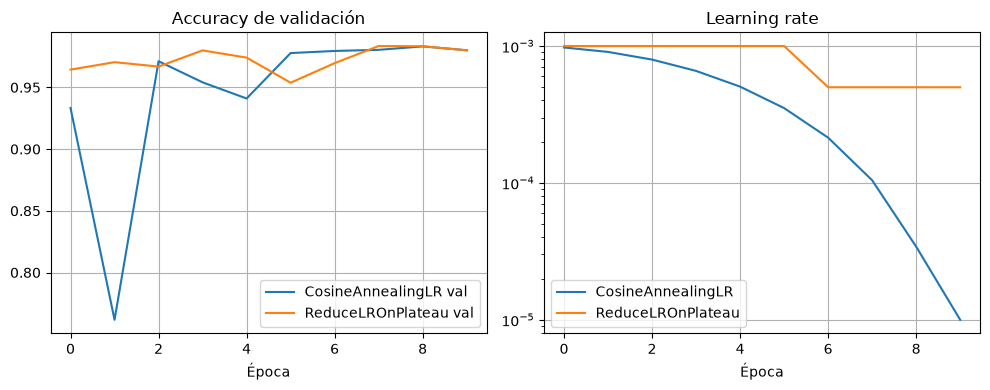


Mejor scheduler: CosineAnnealingLR — Test loss: 0.3062  Test accuracy: 93.22%
CosineAnnealingLR final val acc: 98.01%, ReduceLROnPlateau final val acc: 98.00%


In [18]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
axs[0].plot([h[3] for h in history_cos], label='CosineAnnealingLR val')
axs[0].plot([h[3] for h in history_plateau], label='ReduceLROnPlateau val')
axs[0].set_title('Accuracy de validación'); axs[0].set_xlabel('Época'); axs[0].legend(); axs[0].grid(True)
axs[1].plot([h[4] for h in history_cos], label='CosineAnnealingLR')
axs[1].plot([h[4] for h in history_plateau], label='ReduceLROnPlateau')
axs[1].set_title('Learning rate'); axs[1].set_xlabel('Época'); axs[1].set_yscale('log'); axs[1].legend(); axs[1].grid(True)
plt.tight_layout(); plt.show()

# Evaluación final en test, solo del scheduler ganador en validación
best_model, best_name, best_hist = (
    (model_cos, 'CosineAnnealingLR', history_cos)
    if history_cos[-1][3] > history_plateau[-1][3]
    else (model_plateau, 'ReduceLROnPlateau', history_plateau)
)
loss_fn = nn.CrossEntropyLoss()
best_model.eval(); tesize, tebatches, teloss, teacc = 0, 0, 0, 0
with torch.no_grad():
    for batch in test_loader_sch:
        X, y = batch['X'].to(device), batch['y'].to(device); tesize += len(X); tebatches += 1
        pred = best_model(X); teloss += loss_fn(pred, y).item()
        teacc += (pred.argmax(1) == y).type(torch.float).sum().item()
teloss /= tebatches; teacc /= tesize
print(f"\nMejor scheduler: {best_name} — Test loss: {teloss:.4f}  Test accuracy: {teacc:.2%}")
print(f"CosineAnnealingLR final val acc: {history_cos[-1][3]:.2%}, ReduceLROnPlateau final val acc: {history_plateau[-1][3]:.2%}")

In [22]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             precision_recall_fscore_support, roc_auc_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

labels = ['bladder', 'femur-left', 'femur-right', 'heart', 'kidney-left',
          'kidney-right', 'liver', 'lung-left', 'lung-right', 'pancreas', 'spleen']

@torch.no_grad()
def predict_test(model, loader):
    """Devuelve etiquetas reales, predichas, probabilidades y pérdida media en test."""
    model.eval()
    loss_fn = nn.CrossEntropyLoss(reduction='sum')
    y_true, y_prob, total_loss = [], [], 0.0
    for batch in loader:
        X, y = batch['X'].to(device), batch['y'].to(device)
        logits = model(X)
        total_loss += loss_fn(logits, y).item()
        y_prob.append(torch.softmax(logits, dim=1).cpu().numpy())
        y_true.append(y.cpu().numpy())
    y_true = np.concatenate(y_true)
    y_prob = np.concatenate(y_prob)
    return y_true, y_prob.argmax(1), y_prob, total_loss / len(y_true)

def metricas(y_true, y_pred, y_prob, loss):
    p_m, r_m, f_m, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    _, _, f_w, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted', zero_division=0)
    return {
        'Test loss': loss,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Balanced accuracy': balanced_accuracy_score(y_true, y_pred),
        'Precision (macro)': p_m,
        'Recall (macro)': r_m,
        'F1 (macro)': f_m,
        'F1 (weighted)': f_w,
        'AUC (macro, OvR)': roc_auc_score(y_true, y_prob, multi_class='ovr', average='macro'),
    }

modelos = {'CosineAnnealingLR': model_cos, 'ReduceLROnPlateau': model_plateau}
resultados, preds = {}, {}
for nombre, m in modelos.items():
    y_true, y_pred, y_prob, loss = predict_test(m, test_loader_sch)
    preds[nombre] = (y_true, y_pred)
    resultados[nombre] = metricas(y_true, y_pred, y_prob, loss)

df = pd.DataFrame(resultados).T
print(df.round(4).to_string())

                   Test loss  Accuracy  Balanced accuracy  Precision (macro)  Recall (macro)  F1 (macro)  F1 (weighted)  AUC (macro, OvR)
CosineAnnealingLR     0.3060    0.9322             0.9224             0.9305          0.9224      0.9258          0.932            0.9959
ReduceLROnPlateau     0.3905    0.9137             0.9011             0.9186          0.9011      0.9076          0.913            0.9954


**Comentario:** En validación los dos schedulers terminan prácticamente empatados (98.01% con CosineAnnealingLR frente a 98.00% con ReduceLROnPlateau). Al evaluarlos en test, en cambio, CosineAnnealingLR sale por delante en todas las métricas:

| Métrica (test) | CosineAnnealingLR | ReduceLROnPlateau |
|---|---|---|
| Pérdida | 0.3060 | 0.3905 |
| Accuracy | 93.22% | 91.37% |
| Balanced accuracy | 92.24% | 90.11% |
| F1 (macro) | 92.58% | 90.76% |
| AUC (macro, OvR) | 0.9959 | 0.9954 |

Esto indica que ReduceLROnPlateau falla sobre todo en las clases más difíciles o minoritarias, que son las que pesan igual en las métricas macro y menos en la accuracy global. En ambos modelos la precisión macro es mayor que el recall macro, es decir, tienden a acertar cuando predicen una clase pero dejan escapar casos, y ese desequilibrio es más marcado con ReduceLROnPlateau.

La explicación posible está en cómo evoluciona el learning rate. CosineAnnealingLR lo baja de forma continua hasta 1e-5, de modo que las últimas épocas refinan los pesos con pasos muy pequeños. ReduceLROnPlateau solo lo reduce una vez en 10 épocas (de 1e-3 a 5e-4 en la época 6) y termina con un lr 50 veces mayor que Cosine. Con 10 épocas, este scheduler apenas tiene oportunidad de actuar, en un entrenamiento más largo podría acercarse más al CosineAnnealiingLR.

Respecto al fine-tuning con lr constante del apartado 8 (90.72%), la mejora procede casi toda de CosineAnnealingLR. Así que podemos concluir que bajar el lr de forma progresiva hasta un valor muy pequeño estabiliza el fine-tuning de una red preentrenada.

## 10. Aumento de datos (TL09)

Aplicación de técnicas de *data augmentation* (rotaciones, traslaciones, flips, variaciones de contraste, etc., adecuadas a imágenes médicas) sobre el conjunto de entrenamiento, y estudio de su efecto sobre la precisión final del mejor modelo obtenido hasta el momento (Secciones 8–9).

Tareas de esta sección:
- Definir las transformaciones de aumento de datos utilizadas.
- Entrenar el modelo con y sin aumento de datos, en igualdad de condiciones, y comparar precisión y posible sobreajuste.

El conjunto de transformaciones usado es rotación ±30° y traslación ±10%, se descartan los reflejos de las imágenes porque en el dataset existen etiquetas de clase que son espejo, como femur-left/femur-right, kidney-left/kidney-right, lung-left/lung-right. Reflejar una imagen de riñón izquierdo la convierte visualmente en un riñón derecho sin cambiarle la etiqueta, lo que introduciría ejemplos mal etiquetados. Por eso me limito a rotaciones y traslaciones pequeñas.

In [12]:
from torchvision.transforms import v2

class OrganAMNISTAugDataset(Dataset):
    """Igual que OrganAMNISTDictDataset, pero admite una transformación opcional
    (solo debe pasarse en train; val/test nunca deben perturbarse, TL09)."""
    def __init__(self, images, labels, transform=None):
        self.images = torch.from_numpy(images).float().unsqueeze(1) / 255.0
        self.labels = torch.from_numpy(labels).long()
        self.transform = transform
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        x = self.images[idx]
        if self.transform is not None:
            x = self.transform(x)
        return {'X': x, 'y': self.labels[idx]}

# Aumento de datos: rotaciones y traslaciones pequeñas (sin flips, ver comentario arriba)
train_transform_aug = v2.Compose([
    v2.RandomRotation(degrees=30),
    v2.RandomAffine(degrees=0, translate=(0.1, 0.1)),
])

data = np.load('../data/organamnist_64.npz')

train_ds_plain = OrganAMNISTAugDataset(data['train_images'], data['train_labels'].ravel(), transform=None)
train_ds_aug   = OrganAMNISTAugDataset(data['train_images'], data['train_labels'].ravel(), transform=train_transform_aug)
val_ds_aug     = OrganAMNISTAugDataset(data['val_images'],   data['val_labels'].ravel())   # sin transform
test_ds_aug    = OrganAMNISTAugDataset(data['test_images'],  data['test_labels'].ravel())  # sin transform

train_loader_plain = DataLoader(train_ds_plain, batch_size=32, shuffle=True)
train_loader_aug   = DataLoader(train_ds_aug, batch_size=32, shuffle=True)
val_loader_aug     = DataLoader(val_ds_aug, batch_size=32)
test_loader_aug    = DataLoader(test_ds_aug, batch_size=32)

In [13]:
# Reutilizamos exp_sched y el mejor scheduler encontrado en la Sección 9 (CosineAnnealingLR aquí)
epochs = 10

def entrenar_resnet(train_loader):
    model = timm.create_model(model_name, pretrained=True, num_classes=11, in_chans=1).to(device)
    optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3)
    scheduler = CosineAnnealingLR(optimizer, T_max=epochs * len(train_loader), eta_min=1e-5)
    history = exp_sched(model, device, train_loader, val_loader_aug, optimizer, scheduler, epochs=epochs)
    return model, history

print("=== Sin aumento de datos ===")
model_plain, history_plain = entrenar_resnet(train_loader_plain)

print("\n=== Con aumento de datos ===")
model_aug, history_aug = entrenar_resnet(train_loader_aug)

=== Sin aumento de datos ===
Epoch 0: lr 9.8e-04  train loss 0.3715 acc 89.52% | val loss 0.8532 acc 77.48%
Epoch 1: lr 9.1e-04  train loss 0.1381 acc 95.86% | val loss 0.0917 acc 97.67%
Epoch 2: lr 8.0e-04  train loss 0.0869 acc 97.33% | val loss 0.1294 acc 96.47%
Epoch 3: lr 6.6e-04  train loss 0.0494 acc 98.46% | val loss 0.1297 acc 96.38%
Epoch 4: lr 5.0e-04  train loss 0.0379 acc 98.96% | val loss 0.1032 acc 97.09%
Epoch 5: lr 3.5e-04  train loss 0.0167 acc 99.42% | val loss 0.0728 acc 98.46%
Epoch 6: lr 2.1e-04  train loss 0.0170 acc 99.67% | val loss 0.0805 acc 98.09%
Epoch 7: lr 1.0e-04  train loss 0.0050 acc 99.87% | val loss 0.0795 acc 97.98%
Epoch 8: lr 3.4e-05  train loss 0.0061 acc 99.95% | val loss 0.0774 acc 98.14%
Epoch 9: lr 1.0e-05  train loss 0.0012 acc 99.96% | val loss 0.0723 acc 98.31%

=== Con aumento de datos ===
Epoch 0: lr 9.8e-04  train loss 0.6898 acc 78.76% | val loss 0.7345 acc 87.26%
Epoch 1: lr 9.1e-04  train loss 0.3501 acc 88.30% | val loss 0.1775 acc 

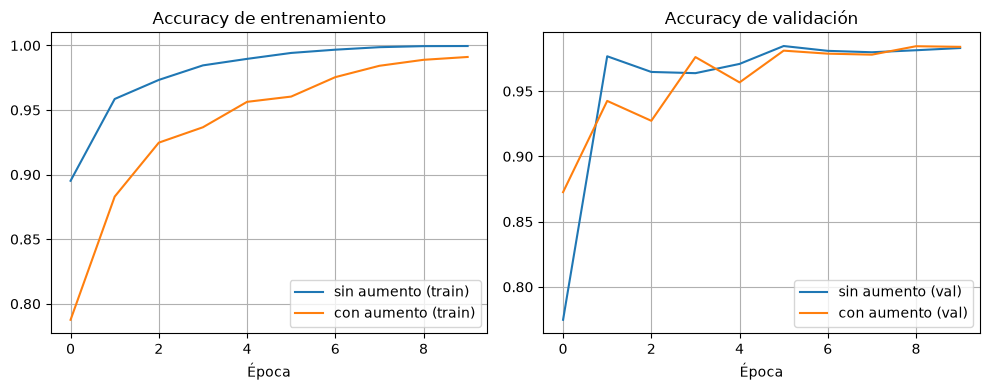

ResNet50 sin aumento — Test accuracy: 94.77%
ResNet50 con aumento — Test accuracy: 94.97%

Gap train-val sin aumento: 1.65%
Gap train-val con aumento: 0.71%


In [14]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for history, label in [(history_plain, 'sin aumento'), (history_aug, 'con aumento')]:
    axs[0].plot([h[1] for h in history], label=f'{label} (train)')
    axs[1].plot([h[3] for h in history], label=f'{label} (val)')
axs[0].set_title('Accuracy de entrenamiento'); axs[0].set_xlabel('Época'); axs[0].legend(); axs[0].grid(True)
axs[1].set_title('Accuracy de validación'); axs[1].set_xlabel('Época'); axs[1].legend(); axs[1].grid(True)
plt.tight_layout(); plt.show()

def eval_test(model, loader):
    loss_fn = nn.CrossEntropyLoss()
    model.eval(); size, batches, total_loss, correct = 0, 0, 0, 0
    with torch.no_grad():
        for batch in loader:
            X, y = batch['X'].to(device), batch['y'].to(device); size += len(X); batches += 1
            pred = model(X); total_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()
    return total_loss / batches, correct / size

loss_plain, acc_plain = eval_test(model_plain, test_loader_aug)
loss_aug, acc_aug = eval_test(model_aug, test_loader_aug)
print(f"ResNet50 sin aumento — Test accuracy: {acc_plain:.2%}")
print(f"ResNet50 con aumento — Test accuracy: {acc_aug:.2%}")
print(f"\nGap train-val sin aumento: {history_plain[-1][1] - history_plain[-1][3]:.2%}")
print(f"Gap train-val con aumento: {history_aug[-1][1] - history_aug[-1][3]:.2%}")

**Comentario:** El aumento de datos (rotación ±30° y traslación ±10%) apenas cambia la precisión final, 94.97% en test con aumento frente a 94.77% sin él. Esta diferencia es demasiado pequeña para considerarla una mejora real, la configuración sin aumento es idéntica a la del apartado 9 con CosineAnnealingLR (mismo lr, scheduler, batch size y épocas) y allí se obtuvo 93.22%, es decir, repetir el mismo entrenamiento con otra inicialización ya varía el test, con más efecto que el aumento.

Sí se observa el efecto regularizador, en la diferencia entre train y validación, sin aumento el modelo memoriza el train (99.96% de acierto, pérdida de 0.0012) y la distancia entre train-val es de 1.65%, mientras que con aumento el train queda en 99.11% (pérdida de 0.0275) y la distancia baja a 0.71%.

Además, por lo que he investigado las imágenes de TC axial tienen una orientación bastante estándar, por lo que rotaciones de hasta 30° pueden estar generando poses poco realistas.

## 11. Modelos no paramétricos: Bosques Aleatorios y XGBoost

Se probarán dos enfoques principales: Bagging mediante Bosques Aleatorios (Random Forest) y Boosting mediante XGBoost. 

Como estos algoritmos no utilizan filtros convolucionales y esperan datos tabulares estructurados, es un requisito previo "aplanar" (flatten) las imágenes 2D para que cada píxel sea tratado como una característica independiente.

En esta sección:

- Aplanar las particiones train, val y test de dimensiones (N, 64, 64) a (N, 4096).

- Entrenar y evaluar un clasificador de Random Forest.

- Entrenar y evaluar un clasificador XGBoost optimizado mediante histogramas para acelerar el procesamiento.

In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from xgboost import XGBClassifier
import time

#Aplanamiento (Flatten)
# Las imágenes de 64x64 se convierten en vectores de 4096 dimensiones
x_train_flat = x_train.reshape(x_train.shape[0], -1)
x_val_flat = x_val.reshape(x_val.shape[0], -1)
x_test_flat = x_test.reshape(x_test.shape[0], -1)

print('Dimensiones train aplanado:', x_train_flat.shape)
print('Dimensiones val aplanado:  ', x_val_flat.shape)
print('Dimensiones test aplanado: ', x_test_flat.shape)


Dimensiones train aplanado: (34561, 4096)
Dimensiones val aplanado:   (6491, 4096)
Dimensiones test aplanado:  (17778, 4096)


### Random Forest

In [16]:

# 2. Modelo Random Forest
print("Entrenando Random Forest...")
start_time = time.time()
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(x_train_flat, y_train)
rf_time = time.time() - start_time

y_pred_val_rf = rf_model.predict(x_val_flat)
acc_val_rf = accuracy_score(y_val, y_pred_val_rf)
print(f"Random Forest entrenado en {rf_time:.2f}s")
print(f"Accuracy Random Forest (Validación): {acc_val_rf:.4f}")



Entrenando Random Forest...
Random Forest entrenado en 52.27s
Accuracy Random Forest (Validación): 0.9524


In [19]:
print(accuracy_score(y_test, rf_model.predict(x_test_flat)))

0.7996400044999438


### XGBoost

In [17]:
# 3. Modelo XGBoost
print("Entrenando XGBoost...")
start_time = time.time()
# Se utiliza tree_method='hist' para optimizar el entrenamiento en datasets grandes y alta dimensionalidad
xgb_model = XGBClassifier(n_estimators=100, learning_rate=0.1, random_state=42, tree_method='hist', n_jobs=-1)
xgb_model.fit(x_train_flat, y_train)
xgb_time = time.time() - start_time

y_pred_val_xgb = xgb_model.predict(x_val_flat)
acc_val_xgb = accuracy_score(y_val, y_pred_val_xgb)
print(f"XGBoost entrenado en {xgb_time:.2f}s")
print(f"Accuracy XGBoost (Validación): {acc_val_xgb:.4f}")

# 4. Evaluación en Test del mejor modelo de ensamble
print("Evaluación en el conjunto de Test (XGBoost):")
y_pred_test_xgb = xgb_model.predict(x_test_flat)
print(classification_report(y_test, y_pred_test_xgb))

Entrenando XGBoost...
XGBoost entrenado en 1295.32s
Accuracy XGBoost (Validación): 0.9496
Evaluación en el conjunto de Test (XGBoost):
              precision    recall  f1-score   support

           0       0.81      0.88      0.84      1036
           1       0.93      0.71      0.80       784
           2       0.91      0.78      0.84       793
           3       0.99      0.77      0.87       785
           4       0.58      0.69      0.63      2064
           5       0.67      0.70      0.68      1965
           6       0.94      0.92      0.93      3285
           7       0.94      0.97      0.96      1747
           8       0.96      0.96      0.96      1813
           9       0.72      0.74      0.73      1622
          10       0.75      0.71      0.73      1884

    accuracy                           0.81     17778
   macro avg       0.84      0.80      0.82     17778
weighted avg       0.82      0.81      0.82     17778



In [23]:
print(accuracy_score(y_test, y_pred_test_xgb))

0.8136460794240072


**Comentario:** Al convertir las imágenes en vectores unidimensionales de 4096 características, los modelos pierden la capacidad de interpretar la patrones espaciales y el contexto local de los píxeles.

Random Forest alcanza 79.96% en test y XGBoost 81.36% (F1 macro de 0.82), por encima de todos los modelos clásicos basados en PCA (QDA 73.89%, regresión logística con polinomios 69.69%, LDA 61.85%) y del MLP (71.44%), pero claramente por debajo de las CNN (LeNet 83.56%, CNN2 88.83%) y del ResNet-50 con fine-tuning (90.72% o más). Podemos confirmar que los píxeles tratados como características independientes tienen un techo en torno al 80%.

La mejora respecto a la regresión logística sobre PCA se nota en casi todas las clases. Comparando con la matriz de confusión del apartado 3, la vejiga pasa de un 33.7% de acierto a un recall de 88%, el bazo de 40.2% a 71%, el páncreas de 55.0% a 74% y los fémures de ~54% a 71-78%. Aun así, el patrón de dificultad se mantiene, los órganos grandes y de alto contraste (pulmones con F1 de 0.96, hígado con 0.93) se clasifican muy bien, y los problemas siguen concentrados en los riñones (F1 de 0.63 el izquierdo y 0.68 el derecho), el páncreas y el bazo (0.73), que son órganos pequeños y de apariencia parecida. En corazón y fémures la precisión es muy alta pero el recall es bajo en comparación, es decir, que cuando predicen esas clases suelen acertar, pero se les escapan bastantes casos.

En cuanto a coste, Random Forest entrena en 52 s y XGBoost en 1295 s (unos 22 minutos), a cambio de una diferencia pequeña. En este problema Random Forest ofrece mejor relación entre coste y precisión.

## 12. Resultados y comparativa global

Tabla resumen con la precisión de validación y test de todos los modelos probados a lo largo del trabajo. La columna de validación recoge la última época de entrenamiento; en los modelos de scikit-learn ajustados con `GridSearchCV` es la media de validación cruzada sobre train (*CV*).

| Modelo | Sección | Precisión val. | Precisión test | Observaciones |
|---|---|---|---|---|
| Regresión logística + PCA (K=100, C=0.1) | Sec. 3 (TL02) | — | 63.97% | Línea base lineal; K elegido con la curva de accuracy frente a K |
| Regresión logística ajustada (K=100) | Sec. 5 (TL04) | 77.25% (CV) | 63.93% | Mejores hiperparámetros C=1 y tol=1e-4; el ajuste no mejora a la base |
| Regresión logística + polinomios grado 2 | Sec. 5 (TL04) | 98.41% (CV) | 69.69% | ~5000 características; la distancia entre CV y test indica sobreajuste |
| LDA (K=120) | Sec. 4 (TL03) | — | 61.85% | Frontera lineal entre clases |
| QDA (K=60) | Sec. 4 (TL03) | — | 73.89% | Mejor modelo clásico sobre PCA (reg_param=0.0966) |
| Regresión lineal (K=100) | Sec. 6 (TL05) | — | 21.72% | R² en test de 0.18; salida redondeada a la clase más cercana |
| Regresión lineal + polinomios grado 2 | Sec. 6 (TL05) | — | 15.74% | R² en test de -0.14; sobreajuste claro |
| MLP | Sec. 7 (TL06) | 90.54% | 71.44% | Sobre los 4096 píxeles aplanados |
| CNN (adaptación de LeNet) | Sec. 7 (TL06) | 94.85% | 83.56% | Converge rápido y estable |
| CNN2 (BatchNorm, Dropout, GAP) | Sec. 7 (TL06) | 93.50% | 88.83% | Mejor red entrenada desde cero |
| ResNet-50 preentrenado, solo cabeza | Sec. 8 (TL07) | 91.16% | 83.34% | 22.539 de 23.5 M parámetros entrenables |
| ResNet-50 preentrenado, fine-tuning completo | Sec. 8 (TL07) | 98.17% | 90.72% | lr constante de 1e-3 |
| ResNet-50 + CosineAnnealingLR | Sec. 9 (TL08) | 98.01% | 93.22% | Balanced accuracy 92.24%, F1 macro 92.58%, AUC 0.9959 |
| ResNet-50 + ReduceLROnPlateau | Sec. 9 (TL08) | 98.00% | 91.37% | Balanced accuracy 90.11%, F1 macro 90.76%, AUC 0.9954 |
| ResNet-50 + Cosine, sin aumento de datos | Sec. 10 (TL09) | 98.31% | 94.77% | Repetición de la configuración de la Sección 9 |
| ResNet-50 + Cosine + aumento de datos | Sec. 10 (TL09) | 98.40% | **94.97%** | Mejor resultado |
| Random Forest  | Sec. 11 | 95.24% | 79.96% | Píxeles aplanados; entrena en 52 s |
| XGBoost  | Sec. 11 | 94.96% | 81.36% | F1 macro de 0.82; entrena en 1295 s (~22 min) |
| *Referencia MedMNIST v2: ResNet-50 a 28×28* | — | — | *93.5%* | Literatura; otra resolución y otro preprocesado |
| *Referencia MedMNIST v2: ResNet-50 a 224×224* | — | — | *94.7%* | Literatura; otra resolución y otro preprocesado |

**Comentario:** La tabla muestra una jerarquía clara en test: los modelos lineales y cuadráticos sobre PCA (≤74%) quedan por debajo del MLP y los árboles, estos por debajo de las CNN entrenadas desde cero (83.6-88.8%), y todas por debajo del ResNet-50 preentrenado con fine-tuning completo (90.7-95.0%). La regresión lineal queda en el último lugar, como era de esperar al tratar las clases como una magnitud continua.

La precisión de validación no sirve para ordenar los modelos más débiles: el MLP alcanza 90.54% en validación y 71.44% en test, y Random Forest pasa de 95.24% a 79.96%. Frente a la literatura, el mejor modelo (94.97% a 64×64) queda en línea con las referencias de ResNet-50 (93.5% a 28×28 y 94.7% a 224×224), pero la comparación no es estricta, porque cambian la resolución, el preprocesado y el protocolo de entrenamiento.

## 13. Conclusiones

El mejor resultado lo obtiene el ResNet-50 preentrenado con fine-tuning completo y CosineAnnealingLR, con 94.77% en test sin aumento de datos y 94.97% con él. Era de esperar, ya que es la arquitectura de referencia del benchmark MedMNIST, combina convoluciones que aprovechan la estructura espacial de la imagen y parte de pesos preentrenados. Aun así, con lr constante el mismo modelo solo llegó a 90.72%, así que la arquitectura por sí sola no explica el resultado, también importa cómo se entrena.

Los modelos clásicos sobre PCA no pasan del 74% (QDA), los ensambles de árboles del 81% y la mejor CNN entrenada desde cero (CNN2) llega a 88.83%, mientras que el ResNet-50 con fine-tuning completo alcanza entre 90.7% y 95.0%. Pero si solo se entrena la cabeza (83.34%), el modelo queda por debajo de CNN2, de modo que las características de ImageNet no se transfieren bien tal cual a cortes de TC en escala de grises y hace falta reajustar toda la red.

Respecto a los schedulers, CosineAnnealingLR mejora el resultado con lr constante (90.72% frente a 93.22%) y también sobre ReduceLROnPlateau (91.37%), aunque con el uso de más épocas seguramente se acercaría más a CosineAnnealingLR. En cuanto al aumento de datos, rotación ±30° y traslación ±10%, no aporta una mejora demostrable.



## 14. Referencias

- Yang, J. et al. *MedMNIST v2 — A Large-Scale Lightweight Benchmark for 2D and 3D Biomedical Image Classification*. _(completar cita completa y enlace)_
- Documentación de `medmnist`: https://medmnist.com/
- Documentación de `timm` (PyTorch Image Models): https://github.com/huggingface/pytorch-image-models
- Documentación de `scikit-learn`: https://scikit-learn.org/
- Documentación de `PyTorch`: https://pytorch.org/
